# Рынок видеоигр и выбор платформ для рекламы

**Учебный проект Яндекс Практикума · аналитика данных**

В декабре 2016 года магазин «Стримчик» планирует кампанию на следующий год. Я сравнил продажи в Северной Америке, Европе и Японии, чтобы выбрать платформы и жанры для каждого региона. Основные выводы опираются на игры, выпущенные в 2014–2016 годах. Сведения за последний год могут быть неполными.

### Содержание

1. [Загрузка и знакомство с данными](#section-1)
2. [Подготовка данных](#section-2)
3. [Исследовательский анализ](#section-3)
4. [Региональные портреты](#section-4)
5. [Проверка гипотез](#section-5)
6. [Выводы и рекомендации](#section-6)

### Основные результаты

| Вопрос | Результат за 2014–2016 годы |
|:--|:--|
| На какие платформы сделать ставку? | PS4 и Xbox One; для Японии отдельно рассмотреть 3DS. |
| Где самый большой объём? | PS4 — **288,15 млн копий**, Xbox One — **140,36 млн**, 3DS — **86,68 млн**. |
| Какой жанр особенно силён на один выпуск? | Shooter: медиана **0,515 млн** против **0,090 млн** у Action. |
| Какие оценки связаны с продажами? | На PS4 корреляция с критиками **0,40**, с пользователями **−0,04**. |
| Что показали гипотезы? | Различие средних XOne и PC не обнаружено; Action оценивают выше Sports. |

Все расчёты, графики и ограничения приведены далее. Продажи измеряются в **миллионах копий**. Данных о выручке, затратах и прибыли нет.

<a id="section-1"></a>
## 1. Загрузка и знакомство с данными

В учебной таблице собраны исторические продажи игр, оценки критиков и игроков, жанры, платформы и возрастные рейтинги ESRB. Одна строка соответствует выпуску игры на конкретной платформе. Одна игра может встретиться несколько раз.

Для повторного запуска нужен исходный файл курса `games.csv`. Ноутбук читает его из своей папки, подпапки `data` или каталога `/datasets`. Графики и таблицы сохранены в результатах ячеек.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import stats
from IPython.display import display

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', '{:,.3f}'.format)

COLORS = {
    'ink': '#18324A', 'blue': '#3267A7', 'teal': '#168B89',
    'orange': '#D48235', 'red': '#B94A48', 'gray': '#8898A6',
    'light': '#E5ECF2', 'purple': '#8566A8',
}
PLATFORM_COLORS = {
    'PS4': '#3267A7', 'XOne': '#168B89', '3DS': '#D48235',
    'PS3': '#8898A6', 'X360': '#8566A8', 'WiiU': '#B94A48',
    'PC': '#647E45', 'PSV': '#AE7198', 'Wii': '#A89B78', 'PSP': '#7E9392',
}
mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'figure.figsize': (11.5, 4.8), 'figure.dpi': 130, 'savefig.dpi': 150,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'text.color': COLORS['ink'], 'axes.labelcolor': COLORS['ink'],
    'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#CBD5DF', 'axes.grid': True,
    'grid.color': '#E5ECF2', 'grid.alpha': 0.8,
    'xtick.color': '#52677A', 'ytick.color': '#52677A',
    'axes.axisbelow': True, 'legend.frameon': False,
})

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__}')

Python 3.12.14 | pandas 3.0.1 | NumPy 2.5.5


In [2]:
def table(frame, formats=None, caption=None):
    """Единое оформление таблиц; исходные числа остаются числовыми."""
    styled = (frame.style
              .format(formats or {}, na_rep='—')
              .set_table_styles([
                  {'selector': 'th', 'props': [('background', '#EDF3F8'),
                                               ('color', '#18324A'), ('text-align', 'left')]},
                  {'selector': 'td', 'props': [('padding', '7px 11px'),
                                               ('border-bottom', '1px solid #E5ECF2')]},
                  {'selector': 'caption', 'props': [('caption-side', 'top'),
                                                    ('text-align', 'left'),
                                                    ('font-weight', '600'), ('padding', '8px 0')]},
              ]))
    if caption:
        styled = styled.set_caption(caption)
    display(styled)


def barh(series, ax, title, xlabel, color=None, percent=False):
    """Горизонтальная диаграмма с нулевой базой и подписями значений."""
    series = series.sort_values(ascending=True)
    values = series.to_numpy(dtype=float)
    colors = color if color is not None else COLORS['blue']
    ax.barh(series.index.astype(str), values, color=colors, height=0.68)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis='y', visible=False)
    ax.set_xlim(0, max(values) * 1.22 if len(values) and max(values) else 1)
    for i, value in enumerate(values):
        label = f'{value:.1f}%' if percent else f'{value:.2f}'
        ax.text(value + max(values) * 0.018, i, label, va='center', fontsize=9)


def finish(fig):
    fig.tight_layout(pad=1.5)
    plt.show()

In [3]:
DATA_CANDIDATES = [
    Path('games.csv'), Path('data/games.csv'),
    Path('/datasets/games.csv'),
]
data_path = next((path for path in DATA_CANDIDATES if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Положите games.csv в папку с ноутбуком или в data/.')

raw = pd.read_csv(data_path)
print(f'Файл: {data_path.name}. Строк: {len(raw):,}. Столбцов: {raw.shape[1]}.')
raw.info()

Файл: games.csv. Строк: 16,715. Столбцов: 11.
<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


Файл содержит **16 715 строк и 11 столбцов**. Доступны название, платформа, год выпуска, жанр, продажи по четырём регионам, две оценки и ESRB.

Продажи и оценка критиков уже представлены числами. Год хранится как `float64`, поскольку есть пропуски; пользовательская оценка — как текст из-за значения `tbd`. Проверим эти особенности перед анализом.

<a id="section-2"></a>
## 2. Подготовка данных

### 2.1. Аудит качества

Сначала измеряем пропуски, затем выбираем обработку. Ноль продаж или оценка 0 — допустимые значения; они не равны отсутствию данных.

In [4]:
quality = pd.DataFrame({
    'Тип': raw.dtypes.astype(str),
    'Пропусков': raw.isna().sum(),
    'Доля пропусков': raw.isna().mean(),
})
table(quality, {'Пропусков': '{:,.0f}', 'Доля пропусков': '{:.1%}'},
      'Пропуски до обработки')
print('Полных дубликатов:', raw.duplicated().sum())
print('Отдельно: tbd в User_Score =', raw['User_Score'].eq('tbd').sum())

,Тип,Пропусков,Доля пропусков
Name,str,2,0.0%
Platform,str,0,0.0%
Year_of_Release,float64,269,1.6%
Genre,str,2,0.0%
NA_sales,float64,0,0.0%
EU_sales,float64,0,0.0%
JP_sales,float64,0,0.0%
Other_sales,float64,0,0.0%
Critic_Score,float64,"8,578",51.3%
User_Score,str,"6,701",40.1%


Полных дубликатов: 0
Отдельно: tbd в User_Score = 2424


### 2.2. Решения по пропускам и типам

| Поле | Обработка | Обоснование |
|:--|:--|:--|
| Все названия столбцов | Нижний регистр | Единый стиль обращения к признакам. |
| `name`, `genre` | Удалить две строки без обоих признаков | Записи нельзя идентифицировать и использовать в жанровом анализе. Потеря — 2,42 млн копий; она показана явно. |
| `year_of_release` | `float64` → nullable `Int64`; пропуски сохранить | Год — целое число. Для 269 записей год неизвестен; угадывание по названию может перепутать версии. Они не попадут во временной срез. |
| `user_score` | `tbd` → `NaN`, затем `float64` | `tbd` означает *to be determined*: итоговая оценка ещё не определена. Это не 0. Вместе с исходными пропусками отсутствуют 9 125 пользовательских оценок. |
| `critic_score` | Оставить числовой тип и `NaN` | Среднее или медиана создали бы вымышленные оценки и исказили корреляции и тесты. |
| `rating` | Сохранить пропуски; создать `rating_group = Unknown` | `Unknown` нужен для полноты региональных долей. Это отсутствие известного ESRB, а не возрастная категория. |
| Региональные продажи | Оставить `float64` | Дробные значения заданы в миллионах копий; пропусков нет. |

**Возможные причины пропусков:** неполнота исходных каталогов, отсутствие достаточного числа отзывов, неоценённые критиками релизы, отсутствие доступного ESRB для части каталога. Эти объяснения правдоподобны, но не подтверждены метаданными. Поэтому не считаем пропуски случайными.

In [5]:
games = raw.copy()
games.columns = games.columns.str.lower()
sales_cols = ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']

unidentified = games['name'].isna() | games['genre'].isna()
removed_rows = int(unidentified.sum())
removed_sales = games.loc[unidentified, sales_cols].sum().sum()
games = games.loc[~unidentified].copy()

games['year_of_release'] = games['year_of_release'].astype('Int64')
games['user_score'] = pd.to_numeric(games['user_score'].replace('tbd', np.nan))
games['rating_group'] = games['rating'].fillna('Unknown')
games['total_sales'] = games[sales_cols].sum(axis=1)

print(f'Удалено строк: {removed_rows}; продажи этих строк: {removed_sales:.2f} млн.')
print(f'Осталось: {len(games):,} записей.')
table(pd.DataFrame({
    'Тип после обработки': games.dtypes.astype(str),
    'Пропусков': games.isna().sum(),
}), {'Пропусков': '{:,.0f}'}, 'Типы и пропуски после подготовки')

Удалено строк: 2; продажи этих строк: 2.42 млн.
Осталось: 16,713 записей.


,Тип после обработки,Пропусков
name,str,0
platform,str,0
year_of_release,Int64,269
genre,str,0
na_sales,float64,0
eu_sales,float64,0
jp_sales,float64,0
other_sales,float64,0
critic_score,float64,"8,576"
user_score,float64,"9,123"


### 2.3. Дубликаты и необычные значения

Совпадение названия на разных платформах ожидаемо. Даже совпадение названия, платформы и года само по себе ещё не позволяет удалять строку: это могут быть разные издания или особенности объединения источников.

In [6]:
key = ['name', 'platform', 'year_of_release']
key_duplicates = games.loc[games.duplicated(key, keep=False)].sort_values(key)
display(key_duplicates)

# Изолированная ранняя запись DS требует отдельного внимания.
ds_years = games.loc[games['platform'].eq('DS'), 'year_of_release'].dropna()
ds_early = games.loc[games['platform'].eq('DS') & games['year_of_release'].eq(ds_years.min())]
display(ds_early[['name', 'platform', 'year_of_release', 'total_sales']])
print('Следующий наблюдаемый год DS:', int(ds_years[ds_years > ds_years.min()].min()))

checks = pd.Series({
    'Полных дубликатов': int(games.duplicated().sum()),
    'Отрицательных региональных продаж': int((games[sales_cols] < 0).sum().sum()),
    'Оценок пользователей вне 0–10': int((~games['user_score'].dropna().between(0, 10)).sum()),
    'Оценок критиков вне 0–100': int((~games['critic_score'].dropna().between(0, 100)).sum()),
    'Дробных годов': int((raw['Year_of_Release'].dropna() % 1 != 0).sum()),
})
display(checks.to_frame('Количество'))

assert games[sales_cols].notna().all().all()
assert (games[sales_cols] >= 0).all().all()
assert games['user_score'].dropna().between(0, 10).all()
assert games['critic_score'].dropna().between(0, 100).all()
assert np.allclose(games['total_sales'], games[sales_cols].sum(axis=1))

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,rating_group,total_sales
604,Madden NFL 13,PS3,2012,Sports,2.110,0.220,0.000,0.230,83.000,5.500,E,E,2.560
16230,Madden NFL 13,PS3,2012,Sports,0.000,0.010,0.000,0.000,83.000,5.500,E,E,0.010


,name,platform,year_of_release,total_sales
15957,Strongest Tokyo University Shogi DS,DS,1985,0.020


Следующий наблюдаемый год DS: 2004


,Количество
Полных дубликатов,0
Отрицательных региональных продаж,0
Оценок пользователей вне 0–10,0
Оценок критиков вне 0–100,0
Дробных годов,0


Обнаружены две строки **Madden NFL 13 / PS3 / 2012** с разными продажами — 2,56 и 0,01 млн. Без подтверждения ошибки сохраняем обе. Они находятся вне будущего основного среза и на его результаты не влияют. Полных дубликатов, отрицательных продаж и оценок вне допустимых диапазонов нет.

У DS есть изолированная запись с **1985** годом и продажами 0,02 млн; следующая группа выпусков начинается в 2004 году. Год выглядит подозрительно, но достоверная замена неизвестна. Сохраняем исходное значение и учитываем эту аномалию при интерпретации жизненного цикла.

**Итог подготовки:** 16 713 записей; оценки не выдуманы; 269 записей без года остаются в общей таблице, но не участвуют во временном анализе. `total_sales` — сумма NA, EU, JP и Other для каждой записи.

<a id="section-3"></a>
## 3. Исследовательский анализ

### 3.1. История выпусков

Исторические данные здесь нужны, чтобы увидеть смену поколений и выбрать актуальный период. После выбора периода все сравнения платформ, жанров, регионов и гипотез строятся только на нём.

> **Как читать временные графики.** Год относится к выпуску игры. Сумма продаж по году — продажи игр соответствующей когорты выпусков, накопленные к моменту сбора данных. Это **не календарные продажи за этот год**. У свежих релизов было меньше времени накопить продажи.

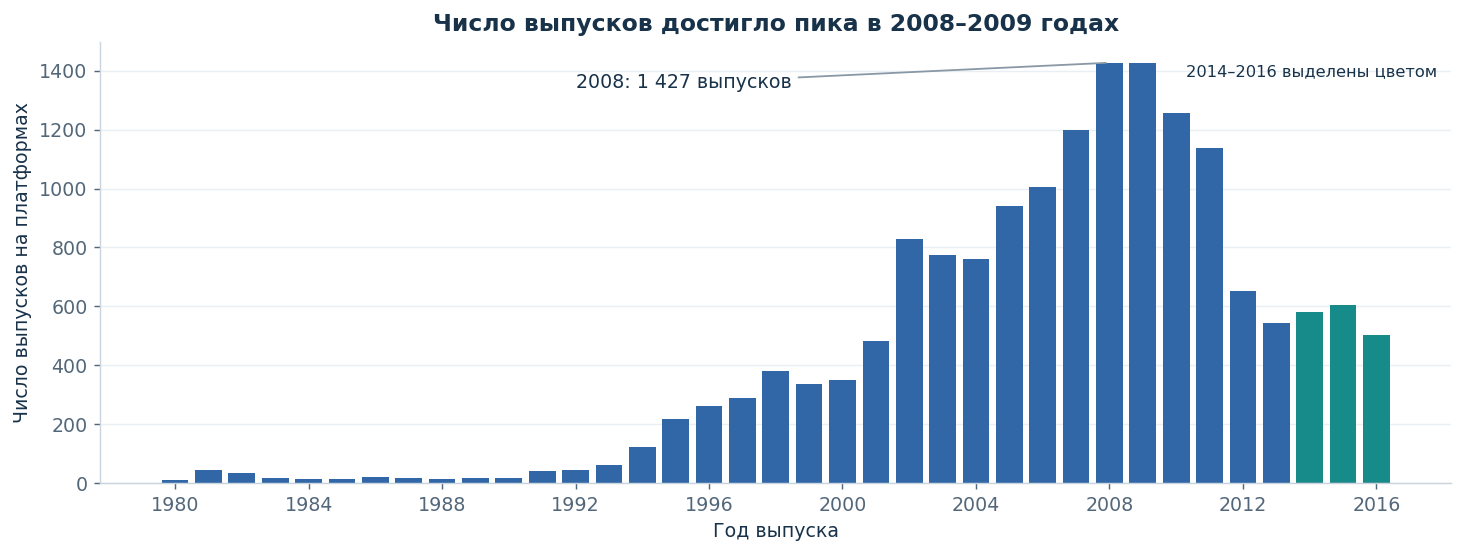

,Выпусков,"Продажи, млн"
year_of_release,,
2012,653,355.84
2013,544,361.24
2014,581,331.53
2015,606,267.98
2016,502,129.94


In [7]:
history = games.dropna(subset=['year_of_release']).copy()
annual = history.groupby('year_of_release').agg(
    releases=('name', 'size'), sales=('total_sales', 'sum'))

fig, ax = plt.subplots(figsize=(11.5, 4.5))
years = annual.index.to_numpy(dtype=int)
colors = [COLORS['teal'] if year >= 2014 else COLORS['blue'] for year in years]
ax.bar(years, annual['releases'], color=colors, width=0.8)
ax.set(title='Число выпусков достигло пика в 2008–2009 годах',
       xlabel='Год выпуска', ylabel='Число выпусков на платформах')
ax.set_xticks(np.arange(1980, 2017, 4))
ax.grid(axis='x', visible=False)
ax.annotate('2008: 1 427 выпусков', xy=(2008, annual.loc[2008, 'releases']),
            xytext=(1992, 1340), arrowprops={'arrowstyle': '-', 'color': COLORS['gray']})
ax.text(0.99, 0.95, '2014–2016 выделены цветом', transform=ax.transAxes,
        ha='right', va='top', fontsize=9)
finish(fig)
table(annual.loc[2012:].rename(columns={'releases': 'Выпусков', 'sales': 'Продажи, млн'}),
      {'Выпусков': '{:,.0f}', 'Продажи, млн': '{:.2f}'}, 'Последние годы в наборе данных')

В начале истории каталог небольшой; максимум приходится на 2008–2009 годы. Затем число представленных выпусков сокращается. По одному этому источнику нельзя объяснить снижение изменением всего игрового рынка: могли меняться охват каталога и способ сбора данных.

Данные 1980–2000-х годов не описывают текущий ассортимент. Для решения на 2017 год важнее платформы, активные в последние годы. Значение 2016 года дополнительно ограничено неполнотой данных.

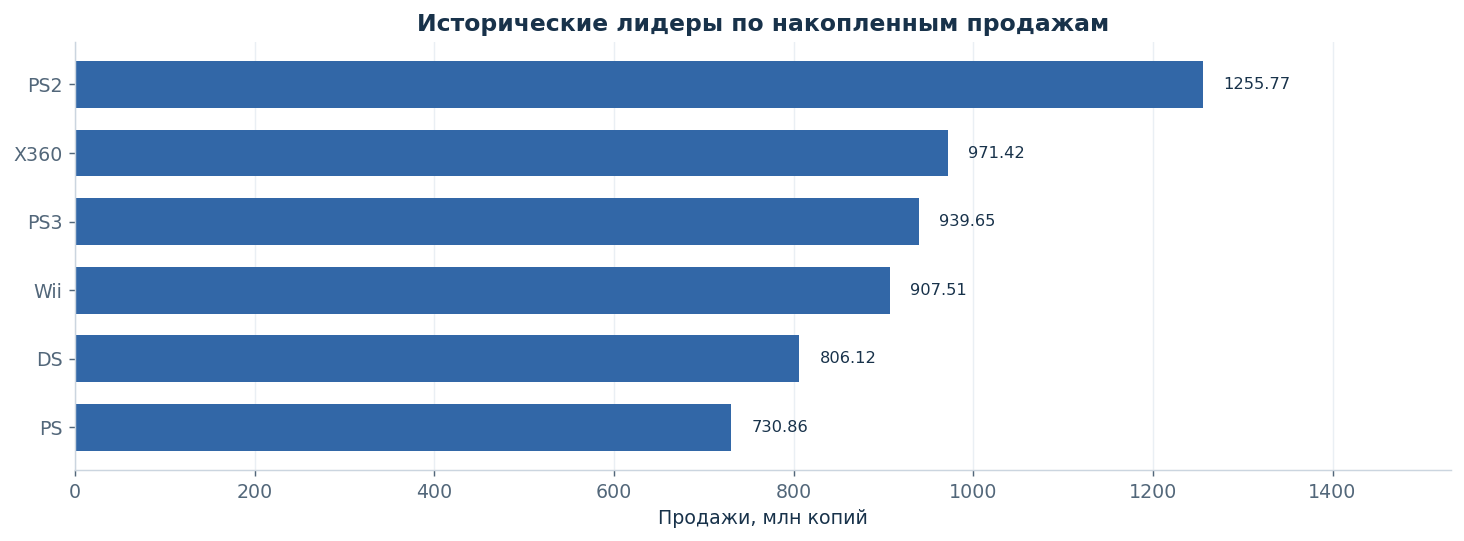

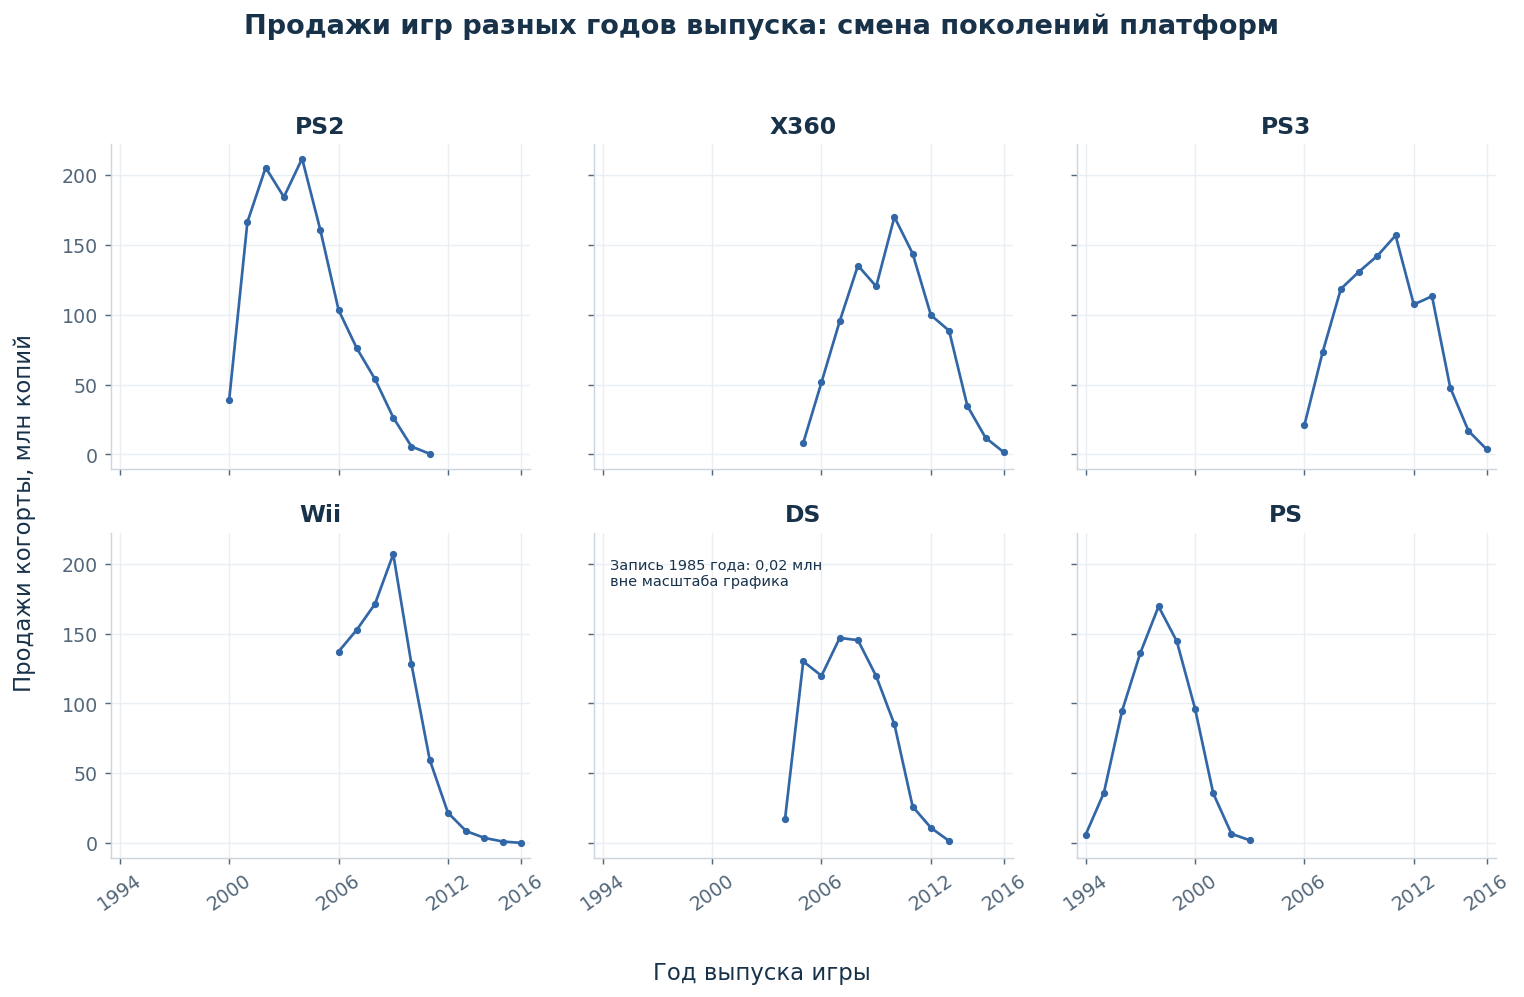

In [8]:
historical_platforms = games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
top_history = historical_platforms.head(6)
fig, ax = plt.subplots(figsize=(11.5, 4.4))
barh(top_history, ax, 'Исторические лидеры по накопленным продажам', 'Продажи, млн копий')
finish(fig)

platform_year = history.groupby(['platform', 'year_of_release'])['total_sales'].sum()
fig, axes = plt.subplots(2, 3, figsize=(12, 7.4), sharex=True, sharey=True)
for ax, platform in zip(axes.flat, top_history.index):
    series = platform_year.loc[platform]
    visible = series.loc[series.index >= 1994]
    ax.plot(visible.index.astype(int), visible, color=COLORS['blue'], marker='o', markersize=3)
    ax.set_title(platform)
    ax.set_xlim(1993.5, 2016.5)
    ax.set_xticks([1994, 2000, 2006, 2012, 2016])
    ax.tick_params(axis='x', rotation=35)
    if platform == 'DS':
        ax.text(0.04, 0.92, 'Запись 1985 года: 0,02 млн\nвне масштаба графика',
                transform=ax.transAxes, fontsize=8, va='top')
fig.suptitle('Продажи игр разных годов выпуска: смена поколений платформ',
             fontsize=15, fontweight='bold', y=1.02)
fig.supxlabel('Год выпуска игры')
fig.supylabel('Продажи когорты, млн копий')
finish(fig)

In [9]:
life_rows = []
for platform in top_history.index:
    series = platform_year.loc[platform].sort_index()
    cumulative = series.cumsum() / series.sum()
    core_start = int(cumulative[cumulative >= 0.05].index[0])
    core_end = int(cumulative[cumulative >= 0.95].index[0])
    first, last = int(series.index.min()), int(series.index.max())
    life_rows.append({
        'Платформа': platform, 'Первый год': first, 'Последний год': last,
        'Наблюдаемое окно, лет': last - first + 1,
        'Начало ядра': core_start, 'Конец ядра': core_end,
        'Ядро, лет': core_end - core_start + 1,
    })
lifecycle = pd.DataFrame(life_rows).set_index('Платформа')
table(lifecycle, {column: '{:.0f}' for column in lifecycle.columns},
      'Жизненный цикл: наблюдаемое окно и центральные 90% продаж по годам выпуска')

,Первый год,Последний год,"Наблюдаемое окно, лет",Начало ядра,Конец ядра,"Ядро, лет"
Платформа,,,,,,
PS2,2000,2011,12,2001,2008,8
X360,2005,2016,12,2006,2014,9
PS3,2006,2016,11,2007,2014,8
Wii,2006,2016,11,2006,2011,6
DS,1985,2013,29,2005,2010,6
PS,1994,2003,10,1995,2001,7


**Как определён цикл.** Наблюдаемое окно — от первого до последнего года выпуска в каталоге, включая оба года. «Ядро» — от года пересечения 5% накопленных продаж до года пересечения 95%; это интервал основной массы продаж, а не официальный срок поддержки платформы.

Для PS2, X360, PS3, Wii и PS наблюдаемое окно составляет **10–12 лет**, а центральная часть — **6–9 лет**. У DS простая разность даёт 29 лет из-за подозрительной записи 1985 года; основная масса продаж приходится на выпуски 2005–2010 годов. Метод центрального интервала устойчив к этой небольшой аномалии.

Новые поколения появляются до полного ухода предыдущих. При этом X360, PS3 и Wii ещё представлены в 2016 году: их окончание наблюдений ограничено границей файла, и это нельзя принять за доказанную дату исчезновения. Универсального срока для всех платформ нет; PC устроен иначе и не имеет единой смены поколения оборудования.

### 3.2. Выбор актуального периода

Берём **2014–2016 годы**. В таблице PS4 и Xbox One появляются в 2013 году; с 2014 года обе платформы имеют уже не только стартовую когорту релизов. Трёхлетний срез отражает переход к новому поколению и сохраняет достаточное число наблюдений.

2016 год включаем как самый свежий доступный сигнал, но его абсолютный объём не сравниваем с предыдущим как полноценный темп рынка. Для оценки направления дополнительно смотрим 2014 → 2015 и доли новых платформ. С этого места **данные до 2014 года не используются**.

In [10]:
START_YEAR, END_YEAR = 2014, 2016
recent = games.loc[games['year_of_release'].between(START_YEAR, END_YEAR)].copy()
assert recent['year_of_release'].between(START_YEAR, END_YEAR).all()

scope = pd.DataFrame({
    'Показатель': ['Выпусков на платформах', 'Уникальных названий', 'Платформ',
                   'Суммарные продажи, млн'],
    'Значение': [f'{len(recent):,}', f'{recent["name"].nunique():,}',
                 str(recent['platform'].nunique()), f'{recent["total_sales"].sum():,.2f}'],
}).set_index('Показатель')
table(scope, caption='Основная выборка: 2014–2016 годы')

coverage = recent[['critic_score', 'user_score', 'rating']].isna().agg(['sum', 'mean']).T
coverage.columns = ['Пропусков', 'Доля пропусков']
table(coverage, {'Пропусков': '{:.0f}', 'Доля пропусков': '{:.1%}'},
      'Покрытие оценок и рейтингов в актуальном периоде')

,Значение
Показатель,
Выпусков на платформах,"1,689"
Уникальных названий,956
Платформ,10
"Суммарные продажи, млн",729.45


,Пропусков,Доля пропусков
critic_score,971,57.5%
user_score,801,47.4%
rating,749,44.3%


В срезе **1 689 выпусков**, **956 уникальных названий**, 10 платформ и 729,45 млн копий. Неизвестны 57,5% оценок критиков, 47,4% пользовательских оценок и 44,3% ESRB. Анализ отзывов относится к оценённой части каталога; выводы могут зависеть от того, какие игры получили оценки.

### 3.3. Лидеры и динамика платформ

year_of_release,2014,2015,2016,Изменение 2014→2015
platform,,,,
PS4,100.00,118.90,69.25,+18.9%
XOne,54.07,60.14,26.15,+11.2%
3DS,43.76,27.78,15.14,-36.5%
PS3,47.76,16.82,3.60,-64.8%
X360,34.74,11.96,1.52,-65.6%
WiiU,22.03,16.35,4.60,-25.8%
PC,13.28,8.52,5.25,-35.8%
PSV,11.90,6.25,4.25,-47.5%
Wii,3.75,1.14,0.18,-69.6%


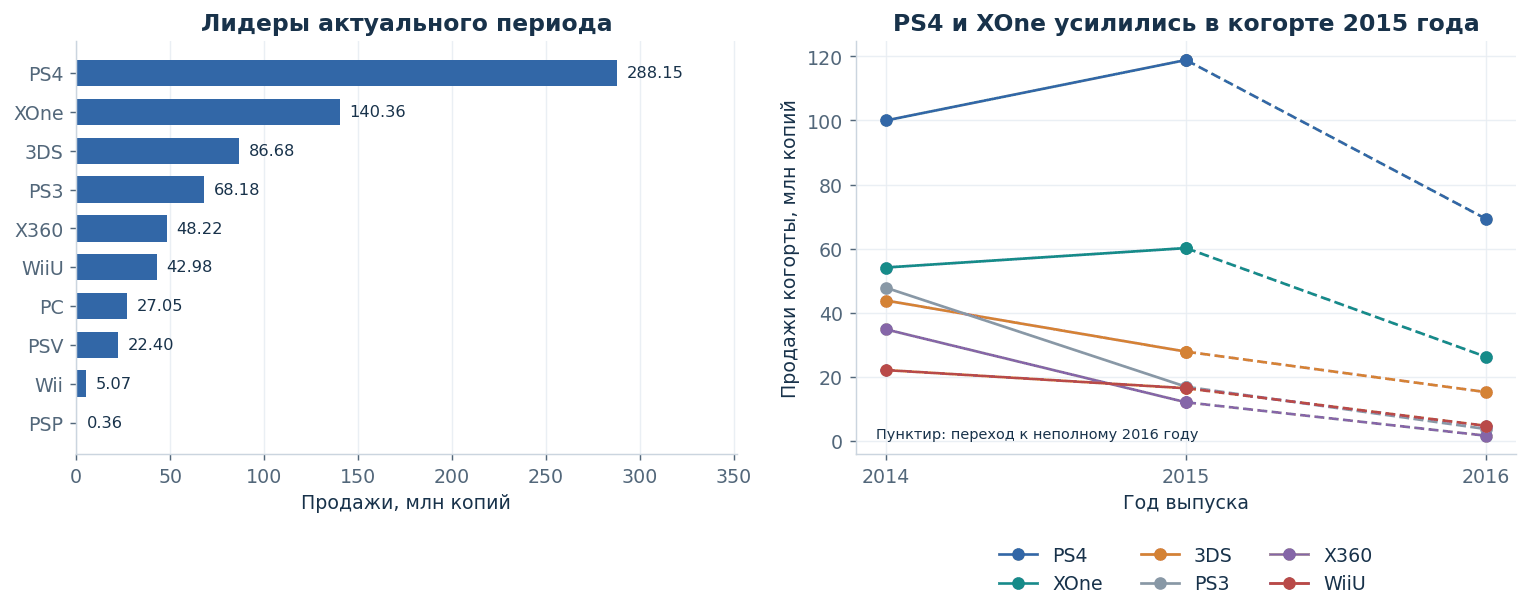

,Доля PS4 + XOne
year_of_release,
2014,46.5%
2015,66.8%
2016,73.4%


In [11]:
platform_summary = (recent.groupby('platform')['total_sales']
                    .agg(releases='size', sales='sum', mean='mean', median='median', maximum='max')
                    .sort_values('sales', ascending=False))
platform_cohorts = recent.pivot_table(index='platform', columns='year_of_release',
                                     values='total_sales', aggfunc='sum', fill_value=0)
platform_cohorts = platform_cohorts.reindex(platform_summary.index)
platform_cohorts['Изменение 2014→2015'] = platform_cohorts[2015] / platform_cohorts[2014] - 1
table(platform_cohorts, {2014: '{:.2f}', 2015: '{:.2f}', 2016: '{:.2f}',
                        'Изменение 2014→2015': '{:+.1%}'},
      'Продажи по году выпуска, млн копий; 2016 год может быть неполным')

fig, axes = plt.subplots(1, 2, figsize=(12, 5.1))
barh(platform_summary['sales'], axes[0], 'Лидеры актуального периода', 'Продажи, млн копий')
for platform in platform_summary.head(6).index:
    series = platform_cohorts.loc[platform, [2014, 2015, 2016]].astype(float)
    color = PLATFORM_COLORS[platform]
    axes[1].plot([2014, 2015], series.loc[[2014, 2015]], color=color, marker='o', label=platform)
    axes[1].plot([2015, 2016], series.loc[[2015, 2016]], color=color, marker='o', linestyle='--')
axes[1].set(title='PS4 и XOne усилились в когорте 2015 года',
            xlabel='Год выпуска', ylabel='Продажи когорты, млн копий', xticks=[2014, 2015, 2016])
axes[1].legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.18))
axes[1].text(0.03, 0.04, 'Пунктир: переход к неполному 2016 году',
             transform=axes[1].transAxes, fontsize=8)
finish(fig)

generation_share = (platform_cohorts.loc[['PS4', 'XOne'], [2014, 2015, 2016]].sum()
                    / platform_cohorts[[2014, 2015, 2016]].sum())
table(generation_share.to_frame('Доля PS4 + XOne'), {'Доля PS4 + XOne': '{:.1%}'},
      'Доля нового поколения в продажах каждой когорты')

**PS4** лидирует по общему объёму — 288,15 млн копий; у **Xbox One** 140,36 млн. Продажи когорты 2015 года выше когорты 2014 года на 18,9% у PS4 и 11,2% у XOne. Их совместная доля увеличивается с **46,5%** для выпусков 2014 года до **66,8%** для выпусков 2015 года и **73,4%** для 2016 года.

**PS3 и X360** резко теряют объём уже между когортами 2014 и 2015 годов. **3DS** также снижается, но остаётся третьей по общему объёму и важна для Японии. **WiiU** имеет отдельные сильные релизы, однако её когортные объёмы сокращаются; **PC** невелик в этом наборе данных.

Основные кандидаты для ассортимента и рекламных кампаний — **PS4, XOne и регионально 3DS**. Более низкие значения 2016 года у всех платформ нельзя трактовать как измеренное падение календарных продаж: влияют неполнота и возраст когорт. Прибыльность по этим данным рассчитать нельзя.

### 3.4. Продажи одного выпуска: распределение по платформам

Сравниваем не только суммы, но и типичный результат выпуска. На полной шкале сохраняем все наблюдения; справа увеличиваем диапазон до 1,5 млн копий для чтения квартилей. Увеличенный фрагмент не участвует в расчётах.

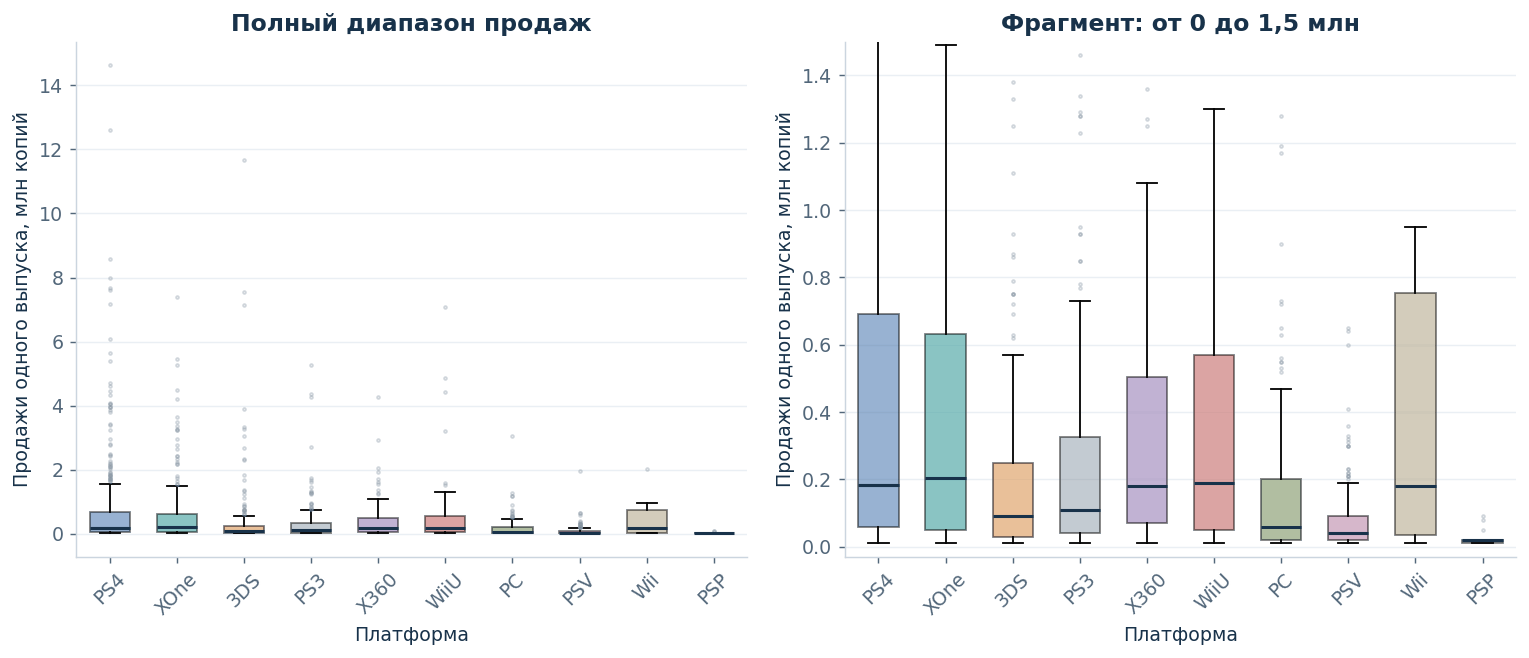

,Выпусков,"Сумма, млн","Среднее, млн","Медиана, млн","Максимум, млн"
platform,,,,,
PS4,376,288.15,0.766,0.185,14.63
XOne,228,140.36,0.616,0.205,7.39
3DS,212,86.68,0.409,0.090,11.68
PS3,219,68.18,0.311,0.110,5.27
X360,111,48.22,0.434,0.180,4.28
WiiU,73,42.98,0.589,0.190,7.09
PC,151,27.05,0.179,0.060,3.05
PSV,295,22.40,0.076,0.040,1.96
Wii,11,5.07,0.461,0.180,2.01


In [12]:
platform_order = platform_summary.index.tolist()
box_data = [recent.loc[recent['platform'].eq(p), 'total_sales'].to_numpy() for p in platform_order]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.3))
for ax in axes:
    box = ax.boxplot(box_data, tick_labels=platform_order, patch_artist=True, widths=0.6,
                     medianprops={'color': COLORS['ink'], 'linewidth': 1.7},
                     flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.4,
                                 'markeredgecolor': COLORS['gray']})
    for patch, platform in zip(box['boxes'], platform_order):
        patch.set(facecolor=PLATFORM_COLORS[platform], alpha=0.5)
    ax.set(xlabel='Платформа', ylabel='Продажи одного выпуска, млн копий')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='x', visible=False)
axes[0].set_title('Полный диапазон продаж')
axes[1].set(title='Фрагмент: от 0 до 1,5 млн', ylim=(-0.03, 1.5))
finish(fig)

table(platform_summary.rename(columns={
    'releases': 'Выпусков', 'sales': 'Сумма, млн', 'mean': 'Среднее, млн',
    'median': 'Медиана, млн', 'maximum': 'Максимум, млн',
}), {'Выпусков': '{:.0f}', 'Сумма, млн': '{:.2f}', 'Среднее, млн': '{:.3f}',
     'Медиана, млн': '{:.3f}', 'Максимум, млн': '{:.2f}'},
      'Среднее, медиана и максимум — разные характеристики продаж')

Распределения скошены вправо: небольшая часть хитов сильно увеличивает среднее. Например, у PS4 среднее составляет **0,766 млн**, а медиана — **0,185 млн**; максимум достигает **14,63 млн**. У XOne медиана немного выше — **0,205 млн**, хотя суммарный объём ниже.

Типичные продажи на PC и PSV в этом каталоге ниже: медианы **0,060** и **0,040 млн** соответственно. Высокая медиана Wii при 11 наблюдениях не делает её перспективной: это маленькая остаточная выборка со снижающимся объёмом.

Границы ящика — 25-й и 75-й процентили, линия внутри — медиана, усы — диапазон до 1,5 межквартильного размаха. Точки за усами — редкие крупные значения; это не доказанные ошибки, поэтому их не удаляем.

### 3.5. Отзывы и продажи

Начнём с PS4 — крупнейшей платформы актуального периода. Для каждой корреляции удаляем только строки без **соответствующей** оценки, а не все строки с любыми пропусками. Нулевые продажи сохраняем.

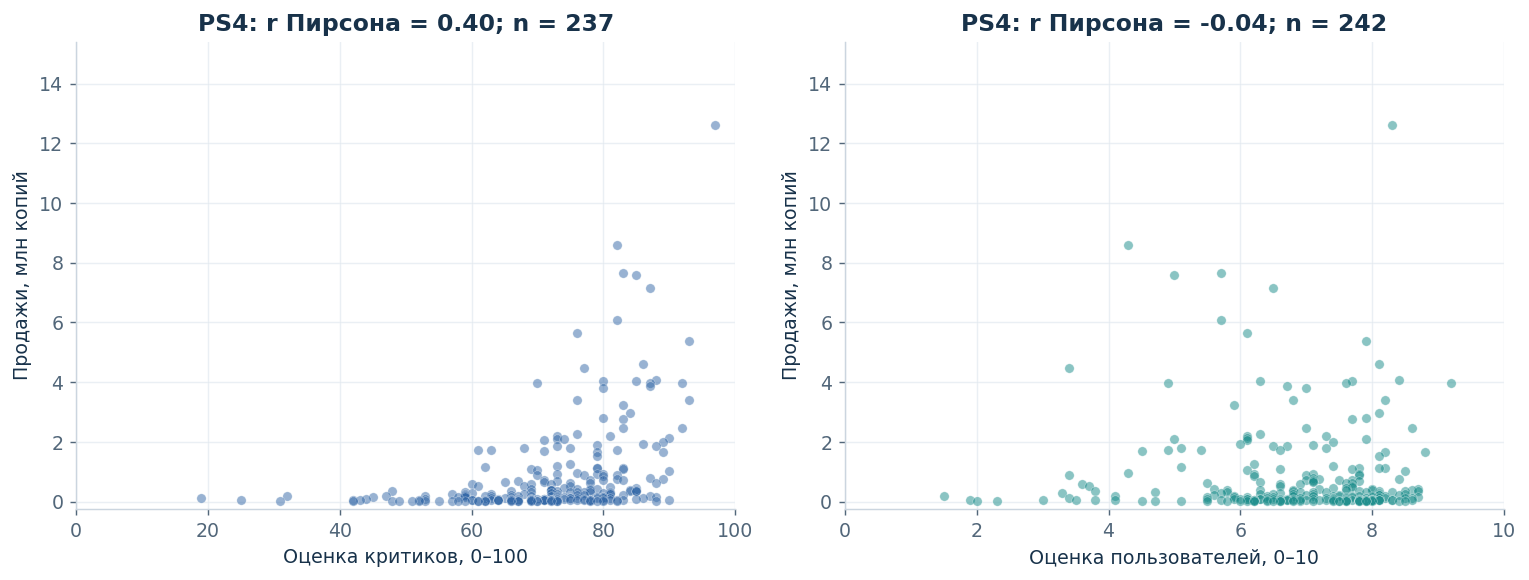

In [13]:
ps4 = recent.loc[recent['platform'].eq('PS4')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, score, label, xmax, color in [
    (axes[0], 'critic_score', 'Оценка критиков, 0–100', 100, COLORS['blue']),
    (axes[1], 'user_score', 'Оценка пользователей, 0–10', 10, COLORS['teal']),
]:
    pairs = ps4[[score, 'total_sales']].dropna()
    r = pairs[score].corr(pairs['total_sales'])
    ax.scatter(pairs[score], pairs['total_sales'], s=27, alpha=0.5,
               c=color, edgecolors='white', linewidths=0.3)
    ax.set(xlabel=label, ylabel='Продажи, млн копий', xlim=(0, xmax), ylim=(-0.25, 15.4))
    ax.set_title(f'PS4: r Пирсона = {r:.2f}; n = {len(pairs)}')
finish(fig)

На PS4 связь продаж с оценкой критиков **умеренно положительная**: `r = 0,403`, 237 наблюдений. С пользовательской оценкой линейная связь практически отсутствует: `r = −0,040`, 242 наблюдения. Высокие оценки не гарантируют хит, а отдельные коммерчески успешные выпуски получают невысокие пользовательские оценки.

Корреляция не устанавливает причинность. Жанр, известность серии, бюджет, маркетинг и возраст игры могут быть связаны одновременно с оценками и продажами. Кроме того, у многих релизов оценок нет.

In [14]:
corr_rows = []
comparison_platforms = ['PS4', 'XOne', '3DS', 'PC', 'WiiU', 'PS3', 'X360', 'PSV']
for platform in comparison_platforms:
    subset = recent.loc[recent['platform'].eq(platform)]
    for score, label in [('critic_score', 'Критики'), ('user_score', 'Пользователи')]:
        pairs = subset[[score, 'total_sales']].dropna()
        corr_rows.append({
            'Платформа': platform, 'Оценка': label, 'Пар': len(pairs),
            'Покрытие': len(pairs) / len(subset),
            'Пирсон r': pairs[score].corr(pairs['total_sales']),
            'Спирмен ρ': pairs[score].corr(pairs['total_sales'], method='spearman'),
        })
correlations = pd.DataFrame(corr_rows).set_index(['Платформа', 'Оценка'])
table(correlations, {'Пар': '{:.0f}', 'Покрытие': '{:.1%}',
                     'Пирсон r': '{:.3f}', 'Спирмен ρ': '{:.3f}'},
      'Сравнение платформ; Спирмен проверяет устойчивость к редким хитам')

На **Xbox One** картина близка к PS4: `r = 0,429` для критиков и `−0,070` для пользователей. На **PC** линейная связь с критиками слабее (`0,175`), пользовательская также близка к нулю (`−0,072`). На **3DS** оценки пользователей связаны с продажами слабо положительно (`0,215`), а на **WiiU** связь заметнее (`0,408`), но выборки невелики.

Ранговая корреляция Спирмена сохраняет положительную связь с критиками на PS4 и XOne, поэтому вывод не сводится к одному крупнейшему хиту. Однако универсальное правило «пользовательские оценки не связаны с продажами на всех платформах» было бы неверным. Применять наблюдения PS4 к остальному каталогу следует с учётом платформы и покрытия оценок.

### 3.6. Жанры: объём каталога и продажи типичного выпуска

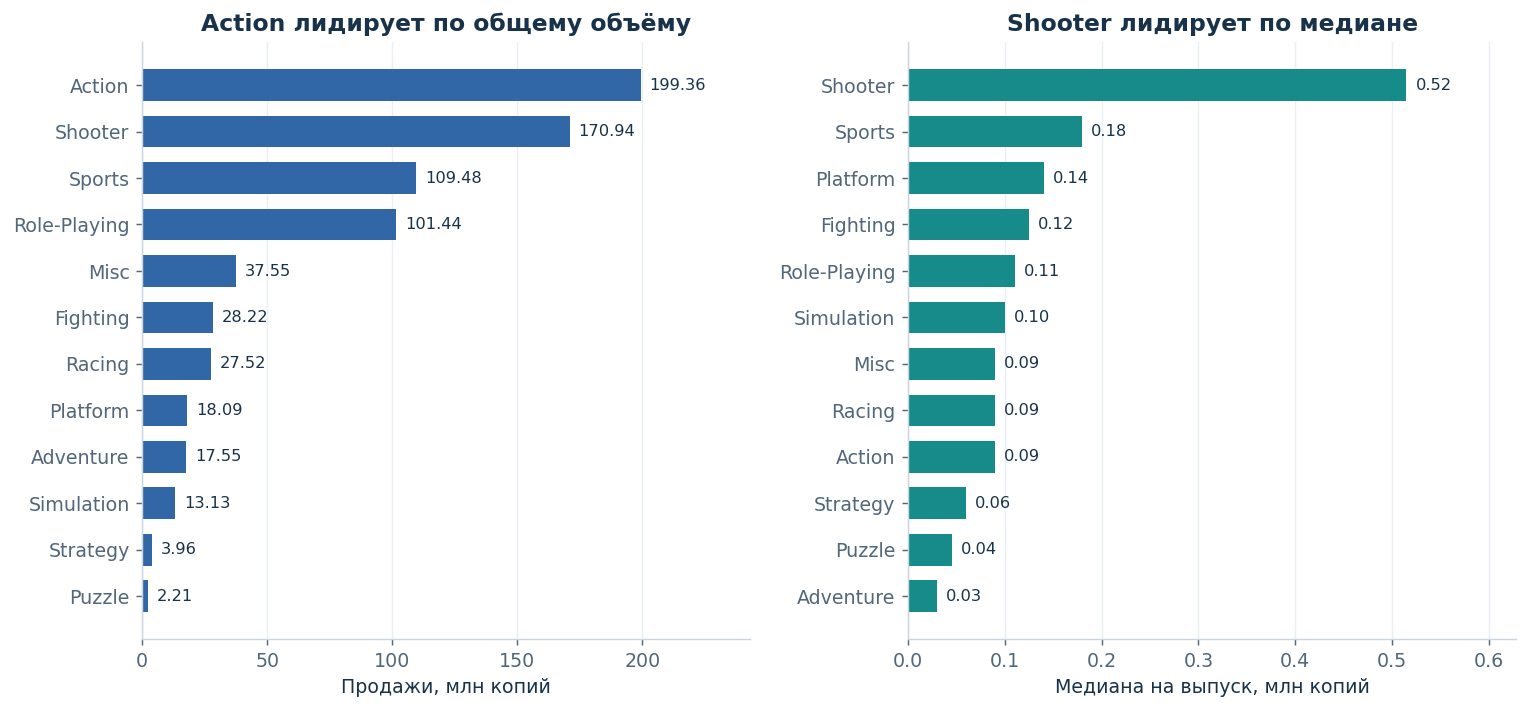

,Выпусков,"Сумма, млн","Среднее, млн","Медиана, млн"
genre,,,,
Action,619,199.36,0.322,0.090
Shooter,128,170.94,1.335,0.515
Sports,161,109.48,0.680,0.180
Role-Playing,221,101.44,0.459,0.110
Misc,113,37.55,0.332,0.090
Fighting,60,28.22,0.470,0.125
Racing,69,27.52,0.399,0.090
Platform,38,18.09,0.476,0.140
Adventure,185,17.55,0.095,0.030


In [15]:
genre_summary = (recent.groupby('genre')['total_sales']
                 .agg(releases='size', sales='sum', mean='mean', median='median')
                 .sort_values('sales', ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.7))
barh(genre_summary['sales'], axes[0], 'Action лидирует по общему объёму', 'Продажи, млн копий')
barh(genre_summary['median'], axes[1], 'Shooter лидирует по медиане',
     'Медиана на выпуск, млн копий', color=COLORS['teal'])
finish(fig)
table(genre_summary.rename(columns={
    'releases': 'Выпусков', 'sales': 'Сумма, млн', 'mean': 'Среднее, млн', 'median': 'Медиана, млн',
}), {'Выпусков': '{:.0f}', 'Сумма, млн': '{:.2f}', 'Среднее, млн': '{:.3f}', 'Медиана, млн': '{:.3f}'},
      'Масштаб и результативность жанров')

**Action** занимает первое место по сумме — **199,36 млн копий**, но включает 619 выпусков и имеет медиану всего **0,090 млн**. Большой объём жанра частично объясняется большим числом предложений.

**Shooter** показывает наиболее высокие типичные продажи: **0,515 млн** по медиане и **1,335 млн** по среднему при 128 выпусках. **Sports** также силён: 109,48 млн суммарно и медиана 0,180 млн. **Role-Playing** входит в лидирующую четвёрку по объёму, а его значение особенно заметно в Японии.

По суммарному объёму невелики **Puzzle** и **Strategy**; у **Adventure** минимальная медиана — 0,030 млн при 185 выпусках. Это различия продаж в наблюдаемом каталоге, а не доказательство прибыльности или убыточности жанра. Затраты разработки и продвижения неизвестны.

<a id="section-4"></a>
## 4. Региональные портреты

Сравниваем NA, EU и JP за **2014–2016 годы**. Доля категории — её продажи, делённые на **все продажи данного региона**, включая категории вне топ-5. `Other_sales` участвует в глобальных суммах, но не является одним из трёх изучаемых регионов.

Портрет описывает структуру проданных копий; данных о возрасте, числе покупателей или индивидуальном поведении нет.

In [16]:
REGIONS = {'na_sales': 'Северная Америка', 'eu_sales': 'Европа', 'jp_sales': 'Япония'}

def regional_top5(data, dimension):
    frames = []
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.7))
    largest_share = 0
    for ax, (region, label) in zip(axes, REGIONS.items()):
        totals = data.groupby(dimension)[region].sum().sort_values(ascending=False)
        top = totals.head(5)
        total = data[region].sum()
        shares = top / total * 100
        largest_share = max(largest_share, shares.max())
        barh(shares, ax, label, 'Доля всех продаж региона, %', percent=True)
        rest = total - top.sum()
        ax.text(0.02, -0.25, f'Остальные: {rest / total:.1%} · Всего: {total:.2f} млн',
                transform=ax.transAxes, fontsize=9)
        top_with_rest = pd.concat([top, pd.Series({'Остальные': rest})])
        frame = pd.DataFrame({'Категория': top_with_rest.index,
                              'Продажи, млн': top_with_rest.values,
                              'Доля региона': top_with_rest.values / total})
        frame.insert(0, 'Регион', label)
        frames.append(frame)
    # Общая шкала нужна для прямого визуального сравнения регионов.
    common_limit = np.ceil(largest_share * 1.18 / 10) * 10
    for ax in axes:
        ax.set_xlim(0, common_limit)
    finish(fig)
    result = pd.concat(frames, ignore_index=True)
    return result.set_index(['Регион', 'Категория'])

### 4.1. Топ-5 платформ

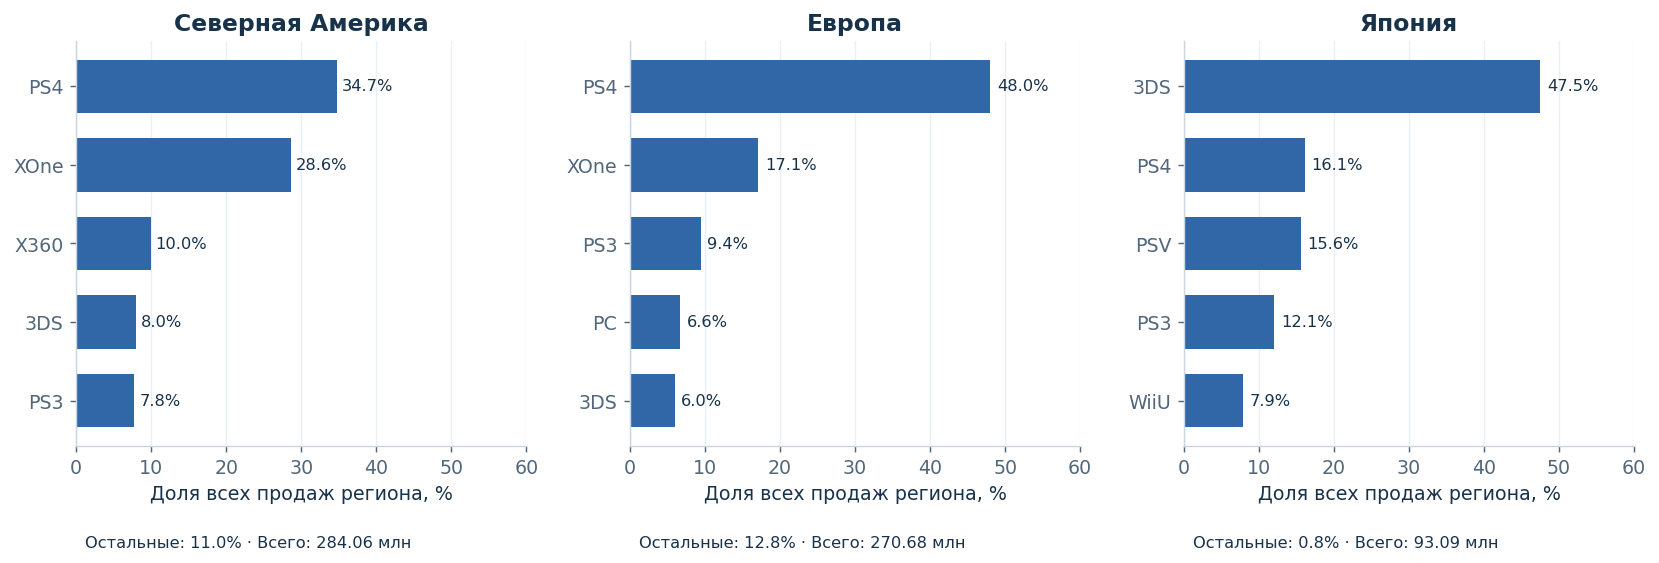

In [17]:
region_platforms = regional_top5(recent, 'platform')
table(region_platforms, {'Продажи, млн': '{:.2f}', 'Доля региона': '{:.1%}'},
      'Платформы: доли от всех продаж региона')

- **Северная Америка:** PS4 — **34,7%**, XOne — **28,6%**. Xbox One существенно ближе к лидеру, чем в других регионах. В топ-5 также остаются X360, 3DS и PS3.
- **Европа:** PS4 занимает **48,0%**, XOne — **17,1%**. Далее идут PS3, PC и 3DS; Европа — единственный из трёх регионов, где PC входит в пятёрку.
- **Япония:** 3DS получает **47,5%**, далее PS4 — **16,1%** и PSV — **15,6%**. Портативные 3DS и PSV вместе дают **63,1%**. В пятёрку входят также PS3 и WiiU; платформы Xbox в неё не попадают.

Единая глобальная кампания упустила бы эти различия. Для западных регионов основной ассортимент связан с PS4/XOne, для Японии нужен отдельный подход с учётом 3DS и портативного каталога.

### 4.2. Топ-5 жанров

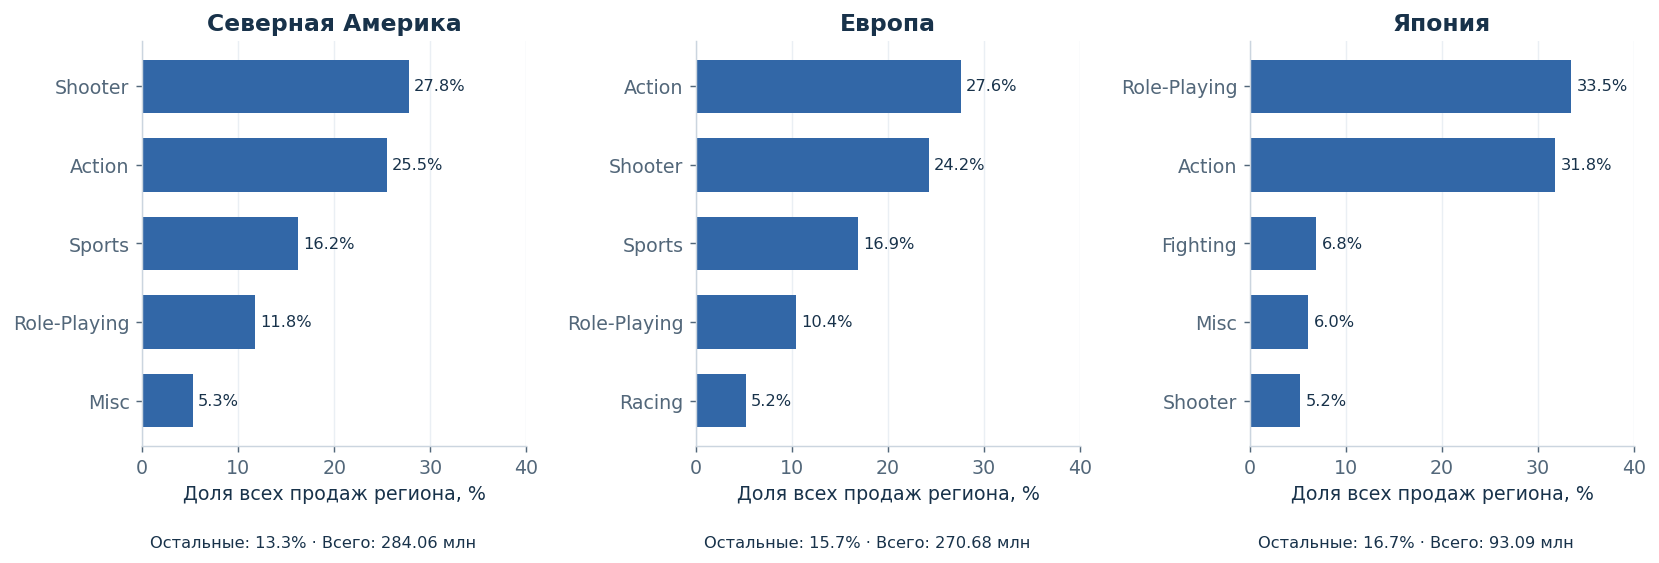

In [18]:
region_genres = regional_top5(recent, 'genre')
table(region_genres, {'Продажи, млн': '{:.2f}', 'Доля региона': '{:.1%}'},
      'Жанры: доли от всех продаж региона')

В **NA** лидирует Shooter (**27,8%**), затем Action (**25,5%**) и Sports (**16,2%**). В **EU** первые два жанра меняются местами: Action (**27,6%**) и Shooter (**24,2%**); Sports занимает **16,9%**. В обеих пятёрках есть Role-Playing; пятое место занимает Misc в NA и Racing в EU.

В **JP** структура другая: Role-Playing (**33,5%**) и Action (**31,8%**) вместе формируют **65,2%** продаж. Далее идут Fighting, Misc и Shooter. Рекламные материалы и подборки для Японии следует строить вокруг RPG и Action, а для NA/EU — учитывать сильный спрос на Shooter и Sports.

Эти показатели описывают отдельные распределения платформ и жанров. Они сами по себе не доказывают, что любая их комбинация будет успешной; перед конкретной закупкой нужно проверить сочетание платформы, жанра и игры.

### 4.3. ESRB и региональные продажи

В актуальном срезе встречаются `E`, `E10+`, `T` и `M`; пропуски показаны как `Unknown`. Буквенные обозначения оставляем в исходной классификации. ESRB — признак контента, а не измеренный возраст покупателя.

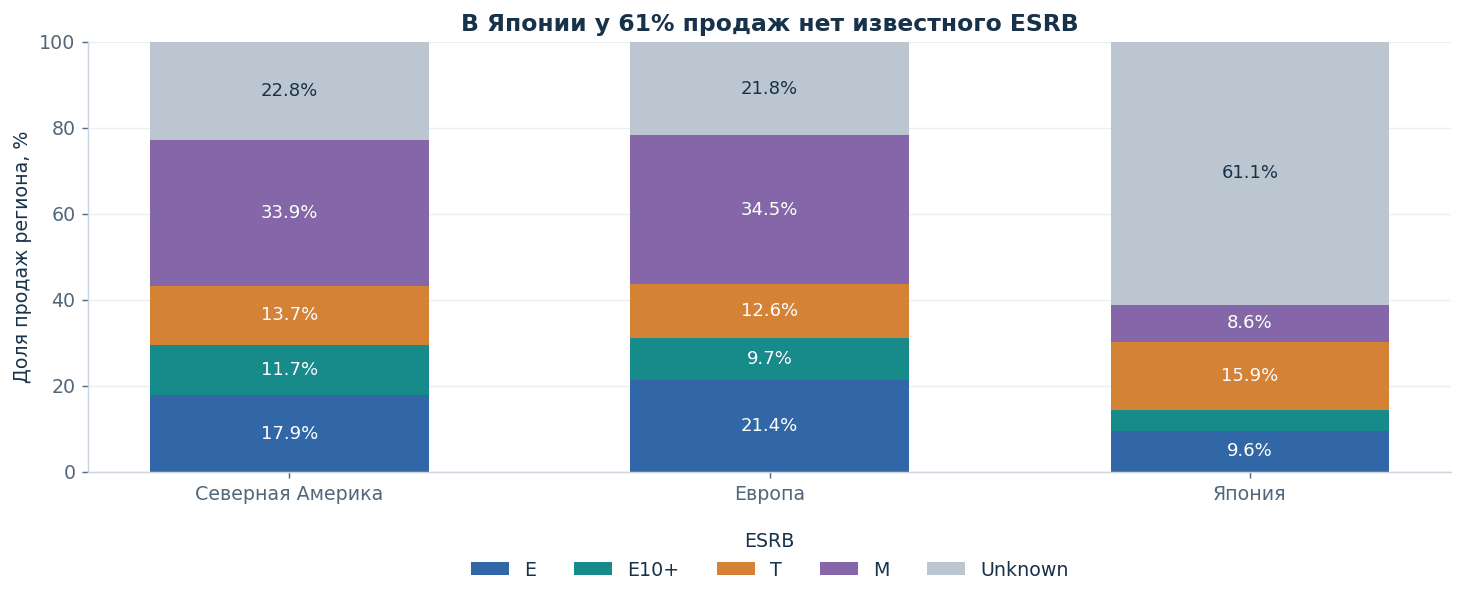

In [19]:
rating_order = ['E', 'E10+', 'T', 'M', 'Unknown']
rating_sales = recent.groupby('rating_group')[list(REGIONS)].sum().reindex(rating_order, fill_value=0)
rating_shares = rating_sales.div(recent[list(REGIONS)].sum(), axis=1)
rating_stats = []
for region, label in REGIONS.items():
    grouped = recent.groupby('rating_group')[region].agg(['size', 'sum', 'mean', 'median'])
    grouped['share'] = grouped['sum'] / recent[region].sum()
    grouped['region'] = label
    rating_stats.append(grouped.reset_index())
rating_detail = pd.concat(rating_stats).set_index(['region', 'rating_group'])

fig, ax = plt.subplots(figsize=(11.5, 4.9))
bottom = np.zeros(3)
rating_colors = ['#3267A7', '#168B89', '#D48235', '#8566A8', '#BCC6D0']
for rating, color in zip(rating_order, rating_colors):
    values = rating_shares.loc[rating].to_numpy(dtype=float) * 100
    ax.bar(list(REGIONS.values()), values, bottom=bottom, label=rating, color=color, width=0.58)
    for x, value, base in zip(range(3), values, bottom):
        if value >= 8:
            ax.text(x, base + value / 2, f'{value:.1f}%', ha='center', va='center',
                    fontsize=10, color=COLORS['ink'] if rating == 'Unknown' else 'white')
    bottom += values
ax.set(title='В Японии у 61% продаж нет известного ESRB',
       ylabel='Доля продаж региона, %', ylim=(0, 100))
ax.grid(axis='x', visible=False)
ax.legend(title='ESRB', ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.10))
finish(fig)

table(rating_detail.rename(columns={
    'size': 'Выпусков', 'sum': 'Продажи, млн', 'mean': 'Среднее, млн',
    'median': 'Медиана, млн', 'share': 'Доля региона',
}), {'Выпусков': '{:.0f}', 'Продажи, млн': '{:.2f}', 'Среднее, млн': '{:.3f}',
     'Медиана, млн': '{:.3f}', 'Доля региона': '{:.1%}'},
      'ESRB: общий объём и продажи на выпуск; включая релизы с нулевыми продажами в регионе')

В **NA** и **EU** среди известных категорий лидирует **M**: 96,42 и 93,44 млн копий соответственно. У этой категории также наиболее высокие средние продажи на выпуск в обоих регионах. По общему объёму далее идёт E.

В **JP** крупнейшая группа — **Unknown: 61,1% продаж**. Среди известных категорий лидирует T — 14,78 млн копий. В NA и EU доля Unknown тоже существенна — **22,8%** и **21,8%**.

Следовательно, структура продаж связана с ESRB и различается по регионам, но **причинное влияние рейтинга не установлено**. Результат может объясняться жанрами, платформами и составом каталога. Особенно осторожно нужно трактовать Японию: большая часть её продаж не имеет известного ESRB. Нельзя заключить, что покупатели Unknown предпочитают определённую возрастную категорию.

<a id="section-5"></a>
## 5. Проверка гипотез

Используем только **2014–2016 годы** и известные пользовательские оценки. Нулевые оценки допустимы и сохраняются. Уровень значимости задаём заранее: **α = 0,05**.

Выбираем **двусторонний t-тест Уэлча** (`equal_var=False`). Нас интересует разность средних; размеры групп и дисперсии могут различаться. Уэлч не требует равенства дисперсий. Группы достаточно велики для приближения распределения средних, однако это не устраняет ограничения данных.

**Предпосылки и границы:** каталог не является случайной выборкой покупателей; оценки есть не у всех выпусков. Один тайтл встречается на нескольких платформах, поэтому независимость строк условна. В частности, среди оценённых XOne и PC есть общие названия. Результаты — учебная проверка средних в представленном каталоге, а не доказательство причинных различий или оценка среднего мнения всех игроков.

95%-й доверительный интервал относится к разности средних **первой группы минус вторая**. Это индивидуальный интервал каждой проверки.

In [20]:
ALPHA = 0.05

def welch_report(data, column, first, second):
    a = data.loc[data[column].eq(first), 'user_score'].dropna()
    b = data.loc[data[column].eq(second), 'user_score'].dropna()
    test = stats.ttest_ind(a, b, equal_var=False, alternative='two-sided')
    # Формула Уэлча–Саттертуэйта делает расчёт интервала явным.
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    standard_error = np.sqrt(va + vb)
    degrees = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    difference = a.mean() - b.mean()
    margin = stats.t.ppf(1 - ALPHA / 2, degrees) * standard_error
    summary = pd.DataFrame({
        'Группа': [first, second], 'n': [len(a), len(b)],
        'Среднее': [a.mean(), b.mean()], 'Медиана': [a.median(), b.median()],
        'Стандартное отклонение': [a.std(), b.std()],
    }).set_index('Группа')
    result = {
        'comparison': f'{first} − {second}', 'n_first': len(a), 'n_second': len(b),
        'difference': difference, 't': test.statistic, 'df': degrees, 'p': test.pvalue,
        'ci_low': difference - margin, 'ci_high': difference + margin,
        'reject': bool(test.pvalue < ALPHA),
    }
    return summary, result

platform_groups, platform_test = welch_report(recent, 'platform', 'XOne', 'PC')
genre_groups, genre_test = welch_report(recent, 'genre', 'Action', 'Sports')

### 5.1. Средние пользовательские оценки Xbox One и PC

- **H₀:** средняя пользовательская оценка выпусков Xbox One равна средней оценке выпусков PC: μ(XOne) = μ(PC).
- **H₁:** средние различаются: μ(XOne) ≠ μ(PC).

Формулировка задания о равенстве становится нулевой гипотезой. Проверка двусторонняя: заранее не предполагаем, какая платформа оценена выше.

In [21]:
table(platform_groups, {'n': '{:.0f}', 'Среднее': '{:.3f}', 'Медиана': '{:.3f}',
                         'Стандартное отклонение': '{:.3f}'}, 'Xbox One и PC: описательные статистики')
print(f't = {platform_test["t"]:.3f}; df = {platform_test["df"]:.1f}; '
      f'p-value = {platform_test["p"]:.6f}')
print(f'Разность средних XOne − PC: {platform_test["difference"]:.3f}; '
      f'95% ДИ [{platform_test["ci_low"]:.3f}; {platform_test["ci_high"]:.3f}].')
print('Решение:', 'отвергаем H₀' if platform_test['reject'] else 'не отвергаем H₀')

known_platforms = recent.loc[recent['user_score'].notna() & recent['platform'].isin(['XOne', 'PC'])]
shared_titles = set(known_platforms.loc[known_platforms['platform'].eq('XOne'), 'name']) & set(
    known_platforms.loc[known_platforms['platform'].eq('PC'), 'name'])
print('Общих названий среди оценённых выпусков XOne и PC:', len(shared_titles))

,n,Среднее,Медиана,Стандартное отклонение
Группа,,,,
XOne,165,6.595,6.800,1.375
PC,122,6.298,6.800,1.703


t = 1.578; df = 226.9; p-value = 0.116014
Разность средних XOne − PC: 0.296; 95% ДИ [-0.074; 0.666].
Решение: не отвергаем H₀
Общих названий среди оценённых выпусков XOne и PC: 73


У Xbox One средняя оценка **6,595** (`n = 165`), у PC — **6,298** (`n = 122`). Разность — **0,296 балла**, 95% ДИ **[−0,074; 0,666]**. `p = 0,116 > 0,05`.

**H₀ не отвергаем:** имеющихся данных недостаточно, чтобы обнаружить различие средних на выбранном уровне значимости. Это не доказывает их равенство; в частности, интервал допускает как небольшую отрицательную, так и положительную разность. Для доказательства практической эквивалентности нужен другой тест и заранее заданная допустимая разница.

### 5.2. Средние пользовательские оценки Action и Sports

- **H₀:** средние пользовательские оценки Action и Sports равны: μ(Action) = μ(Sports).
- **H₁:** средние различаются: μ(Action) ≠ μ(Sports).

Утверждение задания о различии соответствует альтернативной гипотезе. Направление различия определяем после проверки по наблюдаемым средним.

In [22]:
table(genre_groups, {'n': '{:.0f}', 'Среднее': '{:.3f}', 'Медиана': '{:.3f}',
                      'Стандартное отклонение': '{:.3f}'}, 'Action и Sports: описательные статистики')
print(f't = {genre_test["t"]:.3f}; df = {genre_test["df"]:.1f}; '
      f'p-value = {genre_test["p"]:.3e}')
print(f'Разность средних Action − Sports: {genre_test["difference"]:.3f}; '
      f'95% ДИ [{genre_test["ci_low"]:.3f}; {genre_test["ci_high"]:.3f}].')
print('Решение:', 'отвергаем H₀' if genre_test['reject'] else 'не отвергаем H₀')

,n,Среднее,Медиана,Стандартное отклонение
Группа,,,,
Action,297,6.761,7.100,1.378
Sports,127,5.225,5.500,1.857


t = 8.385; df = 187.9; p-value = 1.183e-14
Разность средних Action − Sports: 1.535; 95% ДИ [1.174; 1.897].
Решение: отвергаем H₀


Средняя оценка Action — **6,761** (`n = 297`), Sports — **5,225** (`n = 127`). Разность — **1,535 балла**, 95% ДИ **[1,174; 1,897]**. `p ≈ 1,18 × 10⁻¹⁴ < 0,05`.

**H₀ отвергаем:** данные согласуются с различием средних; в наблюдаемом каталоге Action оценивают выше Sports. Это не означает, что у каждой игры Action оценка выше, и не доказывает влияние самого жанра: состав платформ, серий и лет внутри групп может различаться.

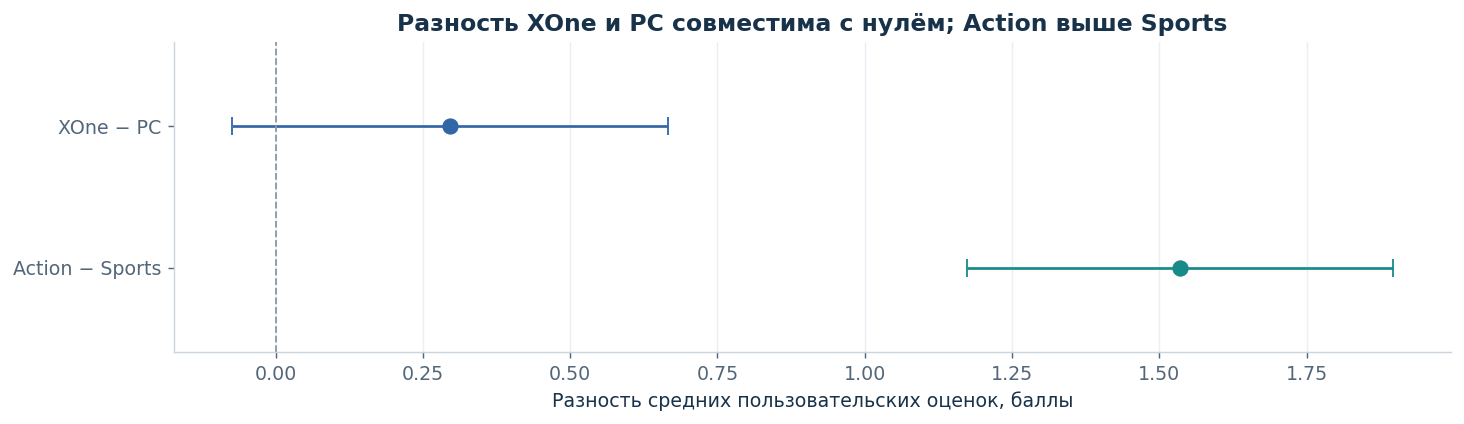

,p-value,"H₀ отвергнута при 0,05","H₀ отвергнута при 0,025"
comparison,,,
XOne − PC,1.160e-01,False,False
Action − Sports,1.183e-14,True,True


In [23]:
test_results = pd.DataFrame([platform_test, genre_test])
fig, ax = plt.subplots(figsize=(11.5, 3.5))
positions = np.arange(len(test_results))
for y, row in test_results.iterrows():
    ax.errorbar(row['difference'], y,
                xerr=[[row['difference'] - row['ci_low']], [row['ci_high'] - row['difference']]],
                fmt='o', capsize=5, markersize=8, color=COLORS['blue'] if y == 0 else COLORS['teal'])
ax.axvline(0, color=COLORS['gray'], linestyle='--', linewidth=1)
ax.set(yticks=positions, yticklabels=test_results['comparison'],
       xlabel='Разность средних пользовательских оценок, баллы',
       title='Разность XOne и PC совместима с нулём; Action выше Sports')
ax.set_ylim(-0.6, 1.6)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
finish(fig)

# Для двух запланированных проверок консервативная поправка Бонферрони
# даёт α / 2 = 0,025. Решения остаются теми же.
test_results['reject_bonferroni'] = test_results['p'] < ALPHA / len(test_results)
table(test_results[['comparison', 'p', 'reject', 'reject_bonferroni']].set_index('comparison')
      .rename(columns={'p': 'p-value', 'reject': 'H₀ отвергнута при 0,05',
                       'reject_bonferroni': 'H₀ отвергнута при 0,025'}),
      {'p-value': '{:.3e}'}, 'Обе проверки: решения устойчивы к поправке на множественность')

<a id="section-6"></a>
## 6. Выводы и рекомендации на 2017 год

### Что показало исследование

1. **Базовый срез — 2014–2016 годы.** Он включает 1 689 выпусков и 729,45 млн копий. История использована для выбора периода, дальнейшие результаты относятся только к этому срезу.
2. **Основной приоритет — PS4 и Xbox One.** Они лидируют по объёму и увеличивают долю относительно предыдущего поколения. У 3DS сохраняется сильная региональная позиция в Японии. PS3 и X360 теряют объём, поэтому их историческая популярность не основание для основной кампании на 2017 год.
3. **Сумма продаж и типичный результат различаются.** Action крупнейший по объёму, а Shooter лидирует по медиане на выпуск. Sports также показывает относительно высокие типичные продажи. Выбор жанра должен учитывать размер каталога и регион.
4. **Оценки критиков полезны как один из сигналов отбора.** На PS4 и XOne связь с продажами умеренно положительная. Пользовательская оценка на этих платформах почти не связана с продажами линейно. Прогнозировать успех по одной оценке нельзя.
5. **Рынки различаются.** NA и EU сильнее ориентированы на PS4/XOne, Shooter, Action и Sports. JP выделяется долей 3DS, портативных платформ, Role-Playing и Action. Среди известных ESRB на Западе лидирует M, в Японии — T, но у 61,1% японских продаж рейтинг неизвестен.
6. **Гипотезы дали разные результаты.** Для XOne и PC различие средних пользовательских оценок не обнаружено (`p = 0,116`). Для Action и Sports различие обнаружено: Action выше примерно на 1,54 балла (`p ≈ 1,18 × 10⁻¹⁴`).

### Как использовать результаты

| Направление | Рекомендация для «Стримчика» | Основание |
|:--|:--|:--|
| Основной ассортимент | В первую очередь рассматривать новые релизы PS4 и XOne | Крупнейшие объёмы актуального периода, усиление доли нового поколения. |
| NA | Учитывать сильную позицию Xbox One наряду с PS4; выделять Shooter и Sports | XOne занимает 28,6%; Shooter и Sports вместе дают 44,1% регионального объёма. |
| EU | Сделать PS4 основной платформой кампании; поддержать подборки Action, Shooter и Sports | PS4 занимает 48,0%; эти три жанра вместе дают 68,7%. |
| JP | Подготовить отдельные подборки 3DS и портативного каталога, RPG и Action; оценивать свежие PS4-релизы отдельно | 3DS занимает 47,5%; RPG и Action вместе дают 65,2%. |
| Выбор конкретных игр | Дополнять платформу и жанр оценкой критиков, известностью серии и доступной информацией о релизе | Оценки связаны с продажами лишь частично; внутри категорий есть сильный разброс. |
| Проверка кампаний | Измерять конверсию, продажи и маржу по региону и игре, сравнивать тестовые кампании | Исторический объём не задаёт рекламную окупаемость или оптимальные доли бюджета. |

### Ограничения решения

Это исследовательская основа для планирования, **не численный прогноз продаж 2017 года**. Продажи накоплены по играм, а не распределены по календарю; 2016 год неполон, свежие релизы наблюдались меньше времени. Неизвестны полнота покрытия источника, цены, рекламные расходы, доступность товара и маржа. Пропуски оценок и ESRB велики; платформенные выпуски одной игры могут зависеть друг от друга.

Перед закупкой и распределением бюджета рекомендации нужно дополнить планом релизов, закупочными ценами, маржой и результатами небольших рекламных тестов. По имеющемуся набору данных обоснованно выбрать приоритеты, но нельзя обещать конкретную прибыль или окупаемость.